In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt

print("Python version:", sys.version.split()[0])
print("NumPy version:", np.__version__)
print("Setup successful! Ready to start the project.")

Python version: 3.13.16
NumPy version: 2.1.3
Setup successful! Ready to start the project.


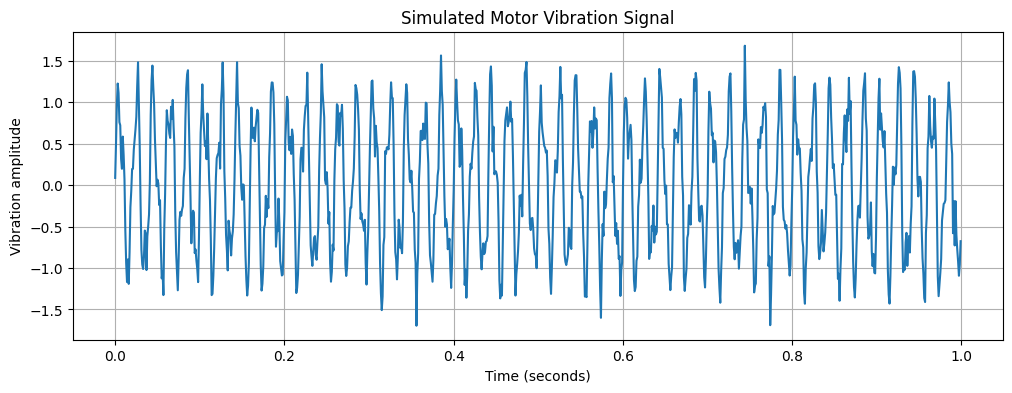

Number of measurements: 1000
Sampling rate: 1000 samples/second


In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Simulate 1 second of vibration measurements
sampling_rate = 1000
time = np.arange(0, 1, 1 / sampling_rate)

# Two vibration frequencies plus small random noise
signal = (
    np.sin(2 * np.pi * 50 * time)
    + 0.4 * np.sin(2 * np.pi * 120 * time)
    + 0.15 * np.random.randn(len(time))
)

# Plot the signal
plt.figure(figsize=(12, 4))
plt.plot(time, signal)
plt.title("Simulated Motor Vibration Signal")
plt.xlabel("Time (seconds)")
plt.ylabel("Vibration amplitude")
plt.grid(True)
plt.show()

print("Number of measurements:", len(signal))
print("Sampling rate:", sampling_rate, "samples/second")

In [3]:
%pip -q install scipy pandas scikit-learn

In [4]:
import requests
from scipy.io import loadmat
import numpy as np
import matplotlib.pyplot as plt

# Download one real experimental recording
url = "https://engineering.case.edu/sites/default/files/105.mat"
response = requests.get(url, timeout=60)
response.raise_for_status()

with open("105.mat", "wb") as file:
    file.write(response.content)

# Read the MATLAB-format data file
data = loadmat("105.mat")

# Display the available variables
keys = [key for key in data.keys() if not key.startswith("__")]
print("Available variables:")
print(keys)

Available variables:
['X105_DE_time', 'X105_FE_time', 'X105_BA_time', 'X105RPM']


Signal variable: X105_DE_time
Number of measurements: 121265
First 10 measurements: [-0.08300435 -0.19573433  0.23341928  0.10395848 -0.18111517  0.05555281
  0.17380559 -0.04694375 -0.1119178   0.05961369]


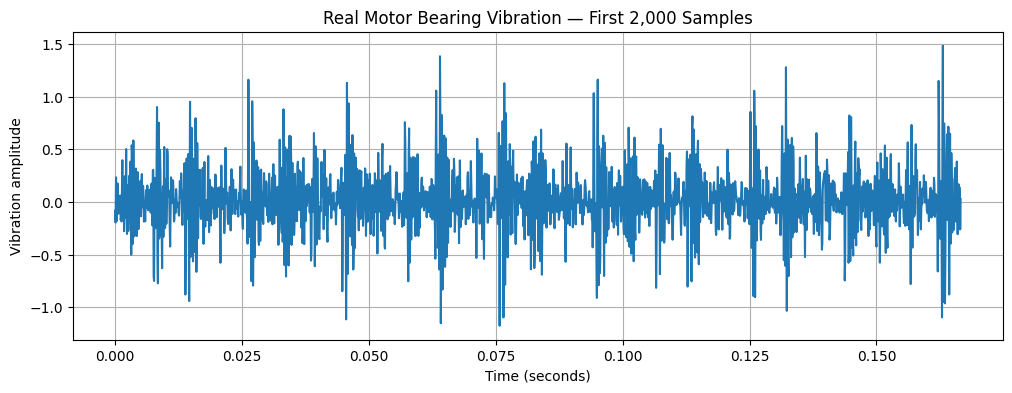

Total recording duration: 10.11 seconds


In [5]:
# Find the drive-end vibration signal automatically
de_key = next(
    key for key in data.keys()
    if key.endswith("DE_time")
)

signal = np.asarray(data[de_key]).squeeze()

print("Signal variable:", de_key)
print("Number of measurements:", len(signal))
print("First 10 measurements:", signal[:10])

# CWRU 12 kHz drive-end recording
sampling_rate = 12000
duration = len(signal) / sampling_rate

time = np.arange(len(signal)) / sampling_rate

plt.figure(figsize=(12, 4))
plt.plot(time[:2000], signal[:2000])
plt.title("Real Motor Bearing Vibration — First 2,000 Samples")
plt.xlabel("Time (seconds)")
plt.ylabel("Vibration amplitude")
plt.grid(True)
plt.show()

print(f"Total recording duration: {duration:.2f} seconds")

In [8]:
import requests
import numpy as np
import pandas as pd
from scipy.io import loadmat
from io import BytesIO
from sklearn.model_selection import train_test_split
from collections import Counter

file_labels = {
    97: 0, 98: 0, 99: 0, 100: 0,
    105: 1, 106: 1, 107: 1, 108: 1,
    118: 2, 119: 2, 120: 2, 121: 2,
    130: 3, 131: 3, 132: 3, 133: 3
}

class_names = {
    0: "Normal",
    1: "Inner-race fault",
    2: "Ball fault",
    3: "Outer-race fault"
}

window_size = 1024
windows_per_file = 150

recordings = {}
record_labels = {}

for file_id, label in file_labels.items():
    url = f"https://engineering.case.edu/sites/default/files/{file_id}.mat"

    response = requests.get(url, timeout=60)
    response.raise_for_status()

    # FIX: Convert response bytes into a file-like object
    mat_data = loadmat(BytesIO(response.content))

    de_key = next(
        (key for key in mat_data if key.endswith("DE_time")),
        None
    )

    if de_key is None:
        raise ValueError(
            f"Drive-end signal not found in {file_id}.mat. "
            f"Available keys: {list(mat_data.keys())}"
        )

    signal = np.asarray(mat_data[de_key]).squeeze()

    recordings[file_id] = signal
    record_labels[file_id] = label

print("Downloaded recordings:", len(recordings))
print("Recording labels:", Counter(record_labels.values()))
print("Dataset loading successful!")

Downloaded recordings: 16
Recording labels: Counter({0: 4, 1: 4, 2: 4, 3: 4})
Dataset loading successful!


In [9]:
# Split entire recording IDs into train and test sets
file_ids = np.array(list(record_labels.keys()))
labels = np.array([record_labels[i] for i in file_ids])

train_ids, test_ids = train_test_split(
    file_ids,
    test_size=0.25,
    random_state=42,
    stratify=labels
)

print("Training recordings:", len(train_ids))
print("Testing recordings:", len(test_ids))

print("\nTraining class counts:")
print(Counter(record_labels[i] for i in train_ids))

print("\nTesting class counts:")
print(Counter(record_labels[i] for i in test_ids))

Training recordings: 12
Testing recordings: 4

Training class counts:
Counter({0: 3, 2: 3, 3: 3, 1: 3})

Testing class counts:
Counter({3: 1, 2: 1, 0: 1, 1: 1})


In [10]:
def make_windows(file_ids):
    X, y = [], []

    for file_id in file_ids:
        signal = recordings[file_id]
        label = record_labels[file_id]

        # Standardize each window independently
        number_of_windows = min(
            windows_per_file,
            len(signal) // window_size
        )

        for i in range(number_of_windows):
            start = i * window_size
            window = signal[start:start + window_size].astype(np.float32)

            mean = window.mean()
            std = window.std()

            window = (window - mean) / (std + 1e-8)

            X.append(window)
            y.append(label)

    return np.array(X, dtype=np.float32), np.array(y, dtype=np.int64)


X_train, y_train = make_windows(train_ids)
X_test, y_test = make_windows(test_ids)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (1519, 1024)
y_train shape: (1519,)
X_test shape: (505, 1024)
y_test shape: (505,)


In [11]:
from sklearn.model_selection import train_test_split
import numpy as np

# Split the original training recordings into training and validation
train_file_ids, val_file_ids = train_test_split(
    train_ids,
    test_size=1/3,
    random_state=42,
    stratify=[record_labels[i] for i in train_ids]
)

# Create windows from separate recordings
X_train, y_train = make_windows(train_file_ids)
X_val, y_val = make_windows(val_file_ids)
X_test, y_test = make_windows(test_ids)

# CNN expects shape: (samples, time_steps, channels)
X_train = X_train[..., np.newaxis]
X_val = X_val[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print("Training data:", X_train.shape, y_train.shape)
print("Validation data:", X_val.shape, y_val.shape)
print("Test data:", X_test.shape, y_test.shape)

Training data: (1013, 1024, 1) (1013,)
Validation data: (506, 1024, 1) (506,)
Test data: (505, 1024, 1) (505,)


In [12]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

# Make results more reproducible
tf.keras.utils.set_random_seed(42)

# Build the 1D CNN
model = models.Sequential([
    layers.Input(shape=(1024, 1)),

    layers.Conv1D(32, kernel_size=7, activation="relu"),
    layers.MaxPooling1D(pool_size=2),

    layers.Conv1D(64, kernel_size=5, activation="relu"),
    layers.MaxPooling1D(pool_size=2),

    layers.Conv1D(128, kernel_size=3, activation="relu"),
    layers.GlobalAveragePooling1D(),

    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(4, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 1018, 32)       │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 509, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 505, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 252, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 250, 128)       │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 43,780 (171.02 KB)

 Trainable params: 43,780 (171.02 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 7s 212ms/step - accuracy: 0.4985 - loss: 1.2076 - val_accuracy: 0.5395 - val_loss: 0.9218
Epoch 2/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 192ms/step - accuracy: 0.7404 - loss: 0.6974 - val_accuracy: 0.7648 - val_loss: 0.4115
Epoch 3/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 201ms/step - accuracy: 0.8144 - loss: 0.3825 - val_accuracy: 0.9901 - val_loss: 0.2586
Epoch 4/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 253ms/step - accuracy: 0.8727 - loss: 0.2758 - val_accuracy: 0.9881 - val_loss: 0.1709
Epoch 5/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 189ms/step - accuracy: 0.9279 - loss: 0.2022 - val_accuracy: 1.0000 - val_loss: 0.0864
Epoch 6/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 172ms/step - accuracy: 0.9684 - loss: 0.1249 - val_accuracy: 1.0000 - val_loss: 0.0380
Epoch 7/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 6s 215ms/step - accuracy: 0.9862 - loss: 0.0735 - val_accuracy: 1.0000 - val_loss: 0.0179
Epoch 8/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 195ms/step - accuracy: 0.9921 - loss: 0.0499 - val_accuracy: 1.

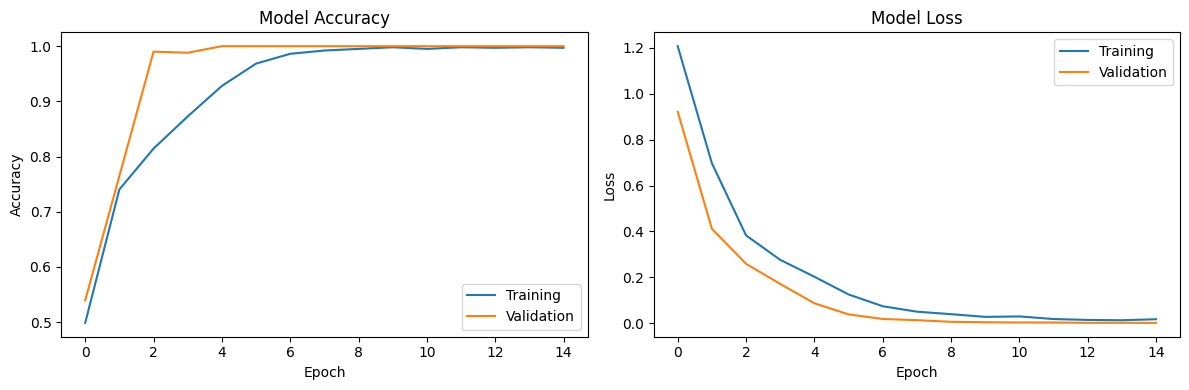

In [14]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 73ms/step
Test accuracy: 1.0000

Classification report:
                  precision    recall  f1-score   support

          Normal       1.00      1.00      1.00       150
Inner-race fault       1.00      1.00      1.00       119
      Ball fault       1.00      1.00      1.00       118
Outer-race fault       1.00      1.00      1.00       118

        accuracy                           1.00       505
       macro avg       1.00      1.00      1.00       505
    weighted avg       1.00      1.00      1.00       505



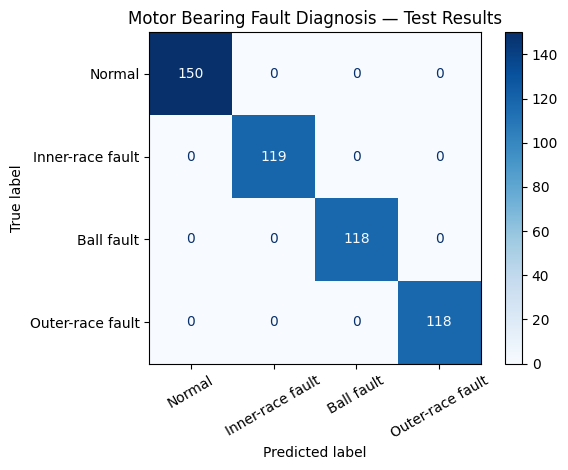

In [15]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import numpy as np

# Predict classes for the untouched test recordings
probabilities = model.predict(X_test)
y_pred = np.argmax(probabilities, axis=1)

# Overall test accuracy
test_accuracy = accuracy_score(y_test, y_pred)
print(f"Test accuracy: {test_accuracy:.4f}")

# Detailed classification metrics
labels = [0, 1, 2, 3]
names = [class_names[i] for i in labels]

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=labels,
    target_names=names,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=labels)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=names
)
display.plot(cmap="Blues", xticks_rotation=30)
plt.title("Motor Bearing Fault Diagnosis — Test Results")
plt.tight_layout()
plt.show()

In [16]:
model.save("motor_bearing_cnn.keras")

print("Model saved successfully!")

Model saved successfully!


In [17]:
from google.colab import files

files.download("motor_bearing_cnn.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
from sklearn.metrics import accuracy_score, classification_report
import numpy as np

y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)

print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nDetailed classification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1, 2, 3],
    target_names=[
        "Normal",
        "Inner-race fault",
        "Ball fault",
        "Outer-race fault"
    ],
    zero_division=0
))

Test accuracy: 1.0

Detailed classification report:
                  precision    recall  f1-score   support

          Normal       1.00      1.00      1.00       150
Inner-race fault       1.00      1.00      1.00       119
      Ball fault       1.00      1.00      1.00       118
Outer-race fault       1.00      1.00      1.00       118

        accuracy                           1.00       505
       macro avg       1.00      1.00      1.00       505
    weighted avg       1.00      1.00      1.00       505



In [19]:
print("TRAIN recordings:")
for file_id in train_file_ids:
    print(f"File {file_id}: class {record_labels[file_id]}")

print("\nVALIDATION recordings:")
for file_id in val_file_ids:
    print(f"File {file_id}: class {record_labels[file_id]}")

print("\nTEST recordings:")
for file_id in test_ids:
    print(f"File {file_id}: class {record_labels[file_id]}")

# Confirm no original recording appears in more than one split
assert set(train_file_ids).isdisjoint(set(val_file_ids))
assert set(train_file_ids).isdisjoint(set(test_ids))
assert set(val_file_ids).isdisjoint(set(test_ids))

print("\nPASS: No original recording is shared between splits.")

TRAIN recordings:
File 108: class 1
File 133: class 3
File 98: class 0
File 121: class 2
File 119: class 2
File 106: class 1
File 100: class 0
File 130: class 3

VALIDATION recordings:
File 97: class 0
File 105: class 1
File 118: class 2
File 131: class 3

TEST recordings:
File 132: class 3
File 120: class 2
File 99: class 0
File 107: class 1

PASS: No original recording is shared between splits.


In [20]:
print("Windows available per recording:")

for file_id in sorted(recordings):
    signal = recordings[file_id].flatten()
    count = len(signal) // window_size

    print(
        f"File {file_id}: "
        f"{len(signal):,} samples, "
        f"{count} complete windows"
    )

Windows available per recording:
File 97: 243,938 samples, 238 complete windows
File 98: 483,903 samples, 472 complete windows
File 99: 483,903 samples, 472 complete windows
File 100: 485,643 samples, 474 complete windows
File 105: 121,265 samples, 118 complete windows
File 106: 121,991 samples, 119 complete windows
File 107: 122,136 samples, 119 complete windows
File 108: 122,917 samples, 120 complete windows
File 118: 122,571 samples, 119 complete windows
File 119: 121,410 samples, 118 complete windows
File 120: 121,556 samples, 118 complete windows
File 121: 121,556 samples, 118 complete windows
File 130: 121,991 samples, 119 complete windows
File 131: 122,426 samples, 119 complete windows
File 132: 121,410 samples, 118 complete windows
File 133: 122,571 samples, 119 complete windows


In [21]:
import numpy as np

class_names = {
    0: "Normal",
    1: "Inner-race fault",
    2: "Ball fault",
    3: "Outer-race fault"
}

def predict_bearing_fault(signal):
    signal = np.asarray(signal).flatten()

    if len(signal) < 1024:
        raise ValueError("Signal must contain at least 1024 samples.")

    # Use the first complete window
    window = signal[:1024].astype(np.float32)

    # Match the preprocessing used during training
    std = window.std()
    if std < 1e-8:
        raise ValueError("Signal has almost no variation.")

    window = (window - window.mean()) / std
    window = window.reshape(1, 1024, 1)

    probabilities = model.predict(window, verbose=0)[0]
    predicted_class = int(np.argmax(probabilities))

    print("Predicted condition:", class_names[predicted_class])
    print(f"Model confidence: {probabilities[predicted_class]:.2%}")

    return probabilities

# Test on a window from a held-out recording
test_signal = recordings[107].flatten()
probabilities = predict_bearing_fault(test_signal)

Predicted condition: Inner-race fault
Model confidence: 99.97%


In [22]:
# Save the trained model
model.save("motor_bearing_cnn.keras")

# Create a class-label file
class_labels = {
    "0": "Normal",
    "1": "Inner-race fault",
    "2": "Ball fault",
    "3": "Outer-race fault"
}

import json

with open("class_labels.json", "w") as f:
    json.dump(class_labels, f, indent=4)

print("Model and class labels saved successfully!")

Model and class labels saved successfully!


In [23]:
from google.colab import files

files.download("motor_bearing_cnn.keras")
files.download("class_labels.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>